# 08 — Telco: Does the economic gain hold up?
**Session 5 · Objective:** Revisit Session 4's training estimate using out-of-fold predictions and a paired customer bootstrap.

Compare **Logistic Regression with original inputs** against **the same model with two added logs**. This is separate from notebook 07's Logistic +logs versus XGBoost +polynomials AP comparison. No AP difference is converted into money.

In [1]:
# Locate the course CSV relative to this notebook, on any operating system.
from pathlib import Path
# Verify that we are using exactly the same CSV bytes as the classroom.
import hashlib
# Report the Python version alongside the numerical results.
import platform
# Work with probability arrays, logarithms and reproducible random samples.
import numpy as np
# Keep customer data and result tables labelled by meaningful column names.
import pandas as pd
# Build the plots step by step, with explicit axes and units.
import matplotlib.pyplot as plt
# Report the installed learning-library version for reproducibility.
import sklearn
# Display more than one table from the same cell.
from IPython.display import display
# Create a fresh, unfitted copy of a model before another training run.
from sklearn.base import clone
# Apply different preprocessing to numeric and categorical inputs.
from sklearn.compose import ColumnTransformer
# Learn missing-value replacements from training customers only.
from sklearn.impute import SimpleImputer
# Keep the Logistic Regression algorithm fixed while testing inputs or policies.
from sklearn.linear_model import LogisticRegression
# Split customers reproducibly and keep churn proportions similar across folds.
from sklearn.model_selection import train_test_split, StratifiedKFold
# Fit preprocessing and the classifier within the same training boundary.
from sklearn.pipeline import Pipeline

# Include SciPy in the recorded environment because it supports the statistical tools.
import scipy

# Scale measured quantities, encode categories and apply row-wise log formulas.
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Evaluate ranking with Average Precision rather than accuracy at an arbitrary cutoff.
from sklearn.metrics import average_precision_score

In [2]:
# Print the actual environment; do not assume it matches the instructor's versions.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__})
# Use readable default figures and remove the two unnecessary border lines.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

# Report the statistical library version as well.
print('SciPy:', scipy.__version__)

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}
SciPy: 1.18.1


In [3]:
# Point from notebooks/ to the CSV committed with this repository.
data_path = Path('../data/telco.csv')
# Fingerprint the file before cleaning so byte-for-byte identity can be checked.
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
# This reference identifies the dataset; it is not a fitted result.
class_fingerprint = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
# Stop if the dataset changed instead of silently comparing incompatible figures.
assert fingerprint == class_fingerprint, 'Dataset differs from class; investigate first.'
# Keep the verified fingerprint visible in the saved output.
print('Dataset SHA-256:', fingerprint)
# Load one row per customer.
df = pd.read_csv(data_path)
# Confirm the expected size and that customers have not been duplicated.
assert df.shape == (7043, 21) and df.customerID.is_unique
# Parse each charge independently; the eleven blank strings become missing values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Exclude both the answer and the identifier from the model inputs.
X = df.drop(columns=['Churn', 'customerID'])
# Encode observed churn as 1 and staying as 0.
y = df['Churn'].eq('Yes').astype(int)

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
# Split row positions so the original classroom order is preserved for score ties.
dev, locked = train_test_split(
    np.arange(len(df)), test_size=.20, stratify=y, random_state=42
)
# Select development inputs and give them consecutive positions for fold indexing.
X_dev = X.iloc[dev].reset_index(drop=True)
# Apply exactly the same selection and index reset to the outcomes.
y_dev = y.iloc[dev].reset_index(drop=True)
# Define shuffled stratified development folds once and reuse them for every candidate.
splitter = StratifiedKFold(5, shuffle=True, random_state=42)
# Store each pair of training and validation positions for later loops.
folds = list(splitter.split(X_dev, y_dev))
# Check that no locked-test position is used for development.
assert set(dev).isdisjoint(locked)
# Report sizes without scoring or inspecting locked-test outcomes.
print(f'Development: {len(dev):,}; locked final test: {len(locked):,}')

Development: 5,634; locked final test: 1,409


## Fix models and policy before calculating value
Both models use C=1, lbfgs, max_iter=2000, training-median imputation, standard scaling and one-hot categories. The augmented model adds log1p(tenure) and log1p(TotalCharges) while retaining original inputs. No calibration, threshold tuning or final-test evaluation is performed.

Use the same five shuffled stratified folds (seed 42). Each development customer gets one probability from a model fitted without that customer. We also refit on all development rows and score those same rows solely to reproduce the earlier **training proxy**, not as validation evidence.

In [5]:
# Name the measured quantities explicitly; SeniorCitizen is a category, not a measurement.
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Collect all remaining original inputs as categorical columns.
CATEGORICAL = []
# Inspect each original column rather than inferring its role from its storage type.
for column in X.columns:
    # Anything outside the three measured quantities is one-hot encoded.
    if column not in NUMERIC:
        # Retain column order so the transformed model inputs stay reproducible.
        CATEGORICAL.append(column)
# Make the course's treatment of the stored 0/1 field explicit.
assert 'SeniorCitizen' in CATEGORICAL

# Define only the row-wise formula; it learns no statistics from other customers.
def add_logs(frame):
    # Copy inputs so another candidate can still use the original columns unchanged.
    result = frame.copy()
    # Compress tenure changes while allowing tenure zero: log1p(x) means log(1 + x).
    result['log_tenure'] = np.log1p(result['tenure'])
    # Missing total charges remain missing until the training imputer handles them.
    result['log_total'] = np.log1p(result['TotalCharges'])
    # Return originals plus the two added inputs.
    return result

# Keep the classroom name for the numeric polynomial input group.
NUM = NUMERIC

In [6]:
# Rebuild an unfitted Pipeline each time so candidates do not share learned statistics.
def build_pipeline(feature_set="raw"):
    # Begin with the original three measured quantities.
    numeric_columns = list(NUMERIC)
    # The baseline passes original inputs straight through.
    feature_step = 'passthrough'
    # Add logs only for the augmented candidate, retaining the original inputs.
    if feature_set == "logs_only":
        # Route the two derived numeric columns through the numeric branch too.
        numeric_columns.extend(['log_tenure', 'log_total'])
        # Adapt the simple row-wise function to the Pipeline's fit/transform interface.
        feature_step = FunctionTransformer(add_logs)
    # Learn numeric replacements and scales inside each training partition.
    numeric_preprocessing = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # Training medians replace missing values.
        ('scale', StandardScaler())  # Training means and standard deviations set the scale.
    ])
    # Keep categorical encoding separate from measured quantities.
    preprocessing = ColumnTransformer([
        ('num', numeric_preprocessing, numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)
    ])
    # Keep the regularization and optimizer identical for the two candidates.
    classifier = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
    # Fit the feature step, preprocessing and classifier within the same boundary.
    return Pipeline([('features', feature_step), ('preprocess', preprocessing),
                     ('model', classifier)])

In [7]:
# Keep OOF probability vectors separate from the optimistic training illustrations.
oof = {}
# These fitted-on-the-same-rows predictions reproduce the earlier training proxy only.
training_scores = {}
# Retain five ranking measurements per representation as a diagnostic.
fold_ap = {}
# Both candidates use Logistic Regression; only the two logs change.
for feature_set in ('raw', 'logs_only'):
    # Missing placeholders expose any development customer who was not scored.
    predictions = np.full(len(y_dev), np.nan)
    # Audit exactly-once OOF coverage independently of the placeholder values.
    validation_count = np.zeros(len(y_dev), dtype=int)
    # Accumulate one AP result for each validation fold.
    scores = []
    # Reuse the exact same customer partitions for raw and added-log inputs.
    for train_positions, validation_positions in folds:
        # No customer can both train and validate the same fitted Pipeline.
        assert set(train_positions).isdisjoint(validation_positions)
        # Build an unfitted copy of this representation.
        candidate = build_pipeline(feature_set)
        # Fit medians, scaling, categories and Logistic Regression on training rows only.
        fitted = candidate.fit(X_dev.iloc[train_positions], y_dev.iloc[train_positions])
        # Save predictions at the original development positions of validation customers.
        predictions[validation_positions] = fitted.predict_proba(X_dev.iloc[validation_positions])[:, 1]
        # Record that these customers have now been validated once.
        validation_count[validation_positions] += 1
        # Score matching outcomes without converting AP into an economic value.
        score = average_precision_score(y_dev.iloc[validation_positions], predictions[validation_positions])
        # Preserve fold-to-fold variation for inspection.
        scores.append(score)
    # Check complete, exactly-once coverage before using the pooled OOF predictions.
    assert np.all(validation_count == 1) and np.isfinite(predictions).all()
    # Save the aligned customer probabilities for campaign ranking and bootstrap.
    oof[feature_set] = predictions
    # Preserve this candidate's five held-out AP measurements.
    fold_ap[feature_set] = scores
    # Refit a new Pipeline on development solely for the labelled training proxy.
    fitted = build_pipeline(feature_set).fit(X_dev, y_dev)
    # These are in-sample predictions and must not be confused with OOF evidence.
    training_scores[feature_set] = fitted.predict_proba(X_dev)[:, 1]
# Label each shared validation fold rather than just printing two score arrays.
fold_table = pd.DataFrame(fold_ap, index=range(1, 6)).rename_axis('Validation fold')
# Round the display while retaining the full probability arrays for economic calculations.
display(fold_table.round(6))

,raw,logs_only
Validation fold,,
1,0.643523,0.652116
2,0.635589,0.653670
3,0.685717,0.693201
4,0.678189,0.682721
5,0.664162,0.680908


## Translate actions into expected value
Contact the highest-scored **20%**, separately for each model, on the same customers. Capacity is fixed, not a probability threshold: `round(0.20 × 5,634) = 1,127` contacts. Descending stable sorting resolves exact ties by development row order. Labels do not set the ranking cutoff.

Class assumptions: €2 call + €20 offer **for every contacted customer**, €300 saved margin per successfully retained would-be churner, and an assumed 40% retention success. A contacted observed churner therefore contributes expected €120 before costs; a contacted non-churner contributes no saved margin.

`expected incremental benefit = 0.40 × €300 × TP − €22 × contacts`

Relative to no intervention, TP contributes +€98, FP −€22, and uncontacted customers €0 incremental value. Churn losses for uncontacted customers cancel against that reference. These are scenario assumptions: Telco observes churn, not the causal effect of an offer.

In [8]:
# Session 5 fixes capacity at the top 20%, rather than choosing a probability cutoff.
CONTACT_FRACTION = .20
# Every contacted customer costs EUR 2 for the call plus EUR 20 for the offer here.
CONTACT_COST = 2 + 20
# This is the assumed preserved margin for a successfully retained would-be churner.
SAVED_MARGIN = 300
# Retention success is an intervention assumption, not estimated from the CSV.
RETENTION_SUCCESS = .40
# Expected saved margin before contact costs is EUR 120 per contacted observed churner.
VALUE_PER_CONTACTED_CHURNER = SAVED_MARGIN * RETENTION_SUCCESS

# Reuse identical capacity and tie handling for both models and every bootstrap draw.
def campaign(scores, target):
    # Match the classroom's round rule, keeping actual-sample capacity as an integer.
    number_of_contacts = int(round(CONTACT_FRACTION * len(target)))
    # Sort highest scores first; stable sorting breaks ties by current row order.
    ranked_positions = np.argsort(-scores, kind='stable')
    # Select exactly the available number of contact places.
    chosen = ranked_positions[:number_of_contacts]
    # Count observed churners among contacted customers.
    true_positives = int(target[chosen].sum())
    # Remaining contacts are to observed stayers.
    false_positives = number_of_contacts - true_positives
    # Observed churn outside the contact list remains undetected.
    false_negatives = int(target.sum()) - true_positives
    # Complete the confusion counts without changing the campaign definition.
    true_negatives = len(target) - true_positives - false_positives - false_negatives
    # No intervention is zero; all uncontacted contributions cancel against that reference.
    benefit = VALUE_PER_CONTACTED_CHURNER * true_positives - CONTACT_COST * number_of_contacts
    # Retain actual totals so the million-customer conversion remains auditable.
    return {'Contacts': number_of_contacts, 'TP': true_positives, 'FP': false_positives,
            'FN': false_negatives, 'TN': true_negatives, 'Expected benefit (EUR)': benefit}

In [9]:
# Apply the same economic accounting when comparing original inputs with added logs.
def value_difference(raw_scores, log_scores, target):
    # Construct the first model's top-20% campaign on the supplied customer sample.
    raw = campaign(raw_scores, target)
    # Rebuild the log model's contact list independently on those same customers.
    logs = campaign(log_scores, target)
    # Calculate the actual-sample difference before changing units.
    difference = logs['Expected benefit (EUR)'] - raw['Expected benefit (EUR)']
    # The denominator is the size of this evaluation population, not the contact list.
    return difference / len(target) * 1_000_000

In [10]:
# Match the positional order of both development probability arrays.
labels = y_dev.to_numpy()
# Keep all actual-sample campaign calculations for audit.
rows = []
# Label in-sample and OOF evaluations so their different evidence quality stays visible.
for evaluation, predictions in [('Training proxy', training_scores), ('Out of fold', oof)]:
    # Evaluate both input representations on the same customer population.
    for feature_set, scores in predictions.items():
        # Build the fixed-capacity campaign before adding presentation labels.
        row = campaign(scores, labels)
        # Identify whether the scores were produced without these customers in training.
        row['Evaluation'] = evaluation
        # Record which input representation generated the ranking.
        row['Inputs'] = feature_set
        # Preserve actual counts and euros rather than scaling them in place.
        rows.append(row)
# Keep the original-sample audit table under meaningful row labels.
value_table = pd.DataFrame(rows).set_index(['Evaluation', 'Inputs'])
# Copy before changing presentation units.
value_per_million = value_table * (1_000_000 / len(labels))
# Label each displayed total with the common population basis.
value_per_million.columns = value_per_million.columns + ' / million'
# Present campaign totals in per-million units while retaining value_table for audit.
display(value_per_million)
# Compute the in-sample difference only to reproduce the earlier training illustration.
train_delta = value_difference(training_scores['raw'], training_scores['logs_only'], labels)
# Use held-out predictions for the exploratory development comparison.
oof_delta = value_difference(oof['raw'], oof['logs_only'], labels)
# State units explicitly for the training proxy.
print(f'Training proxy gain per million: EUR {train_delta:,.2f}')
# Distinguish the OOF estimate from the proxy above.
print(f'OOF gain per million: EUR {oof_delta:,.2f}')

Contacts / million   TP / million  FP / million  \
Evaluation     Inputs                                                       
Training proxy raw             200035.498758  137025.204118  63010.294640   
               logs_only       200035.498758  138090.166844  61945.331913   
Out of fold    raw             200035.498758  134717.784878  65317.713880   
               logs_only       200035.498758  136670.216542  63365.282215   

                           FN / million   TN / million  \
Evaluation     Inputs                                    
Training proxy raw        128328.008520  671636.492723   
               logs_only  127263.045793  672701.455449   
Out of fold    raw        130635.427760  669329.073482   
               logs_only  128682.996095  671281.505147   

                          Expected benefit (EUR) / million  
Evaluation     Inputs                                       
Training proxy raw                            1.204224e+07  
               logs_only                      1.217004e+07  
Out of fold    raw                            1.176535e+07  
               logs_only                      1.199965e+07

Training proxy gain per million: EUR 127,795.53
OOF gain per million: EUR 234,291.80


## Rebuild both campaigns in each paired bootstrap draw
Resample 5,634 development rows with replacement **5,000 times**, using NumPy `default_rng(5262026)`. Each row keeps its label and both fixed OOF scores. Recompute the top-20% contact list for each model in every resample, including the stable tie rule. Duplicated rows represent repeated draws of customers and may occupy multiple places.

Calculate the benefit difference per million in each draw. Use the 2.5th and 97.5th percentiles (`np.quantile`, default linear interpolation). Models are **not refitted** during this bootstrap.

In [11]:
# Use the original Session 5 seed; this differs from the Session 6 protocol.
rng = np.random.default_rng(5262026)
# Allocate one per-million value difference per paired resample.
bootstrap_value = np.empty(5000)
# Resample the actual development population, not the extrapolated campaign size.
n = len(labels)
# Models remain fixed, but capacity-based contact lists are rebuilt within each draw.
for draw in range(len(bootstrap_value)):
    # Keep outcomes and both scores together by sharing the sampled customer positions.
    sampled_positions = rng.integers(0, n, n)
    # Select the original model's fixed scores for these sampled customers.
    sampled_raw = oof['raw'][sampled_positions]
    # Select the log model's scores at exactly the same positions.
    sampled_logs = oof['logs_only'][sampled_positions]
    # The same resampled outcomes evaluate both rebuilt campaigns.
    sampled_labels = labels[sampled_positions]
    # Recompute both top-20% lists and store their per-million value difference.
    bootstrap_value[draw] = value_difference(sampled_raw, sampled_logs, sampled_labels)
# Both bounds already have per-million units because value_difference applies that conversion.
lo, hi = np.quantile(bootstrap_value, [.025, .975])
# Retain the actual OOF point estimate rather than reporting the bootstrap mean.
print(f'OOF estimate per million: EUR {oof_delta:,.0f}')
# Label this as an exploratory conditional interval, not uncertainty about the offer's causal effect.
print(f'Exploratory approximate 95% interval: EUR {lo:,.0f} to EUR {hi:,.0f}')

OOF estimate per million: EUR 234,292
Exploratory approximate 95% interval: EUR -149,627 to EUR 575,080


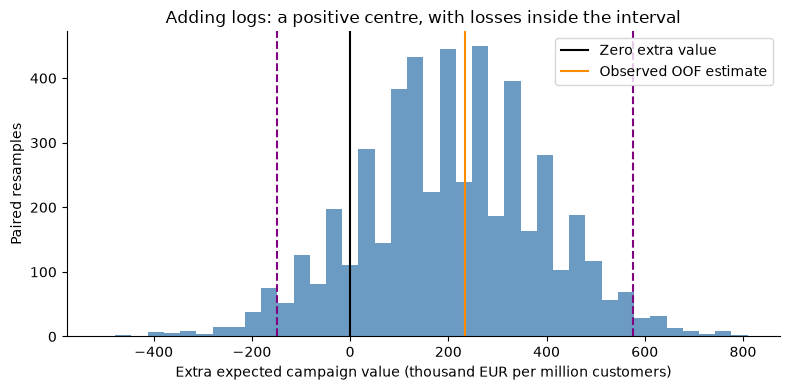

In [12]:
# Express horizontal values in thousands of euros per million to shorten tick labels.
plt.hist(bootstrap_value / 1000, bins=40, color='steelblue', alpha=.8)
# Zero marks no extra expected value from the added-log campaign.
plt.axvline(0, color='black', label='Zero extra value')
# Show the actual OOF estimate separately from the bootstrap distribution.
plt.axvline(oof_delta / 1000, color='darkorange', label='Observed OOF estimate')
# Draw both percentile limits in the same thousands-of-euros plotting unit.
for bound in (lo, hi):
    # Use dashed lines for bounds rather than additional point estimates.
    plt.axvline(bound / 1000, color='purple', linestyle='--')
# State the economic unit and the campaign population basis.
plt.xlabel('Extra expected campaign value (thousand EUR per million customers)')
# Counts refer to paired resampling draws, not new customer observations.
plt.ylabel('Paired resamples')
# Reflect that the calculated interval includes negative differences.
plt.title('Adding logs: a positive centre, with losses inside the interval')
# Identify the two solid reference lines.
plt.legend()
# Keep the long reporting-unit label visible.
plt.tight_layout()
# Display uncertainty only after the fixed policy and accounting have been explained.
plt.show()

## Contrast the calculated figures with class
Values labelled **Class reference** below are comparison targets, not calculation inputs. Compare unrounded figures before presenting rounded euros. The hash confirms byte-for-byte dataset identity. OOF row order and stable sorting matter for reproducibility.

In [13]:
# Classroom values below are verification targets, never inputs to campaign calculations.
check = pd.DataFrame({'Calculated EUR / million': [train_delta, oof_delta, lo, hi],
                      'Class reference EUR / million': [127795.52715654952, 234291.79978700745,
                                                        -149627.26304579322, 575079.8722044729]},
                     index=['Training proxy', 'OOF estimate', 'Bootstrap 2.5%', 'Bootstrap 97.5%'])
# Use named columns so the subtraction does not depend on physical column positions.
check['Difference from class'] = check['Calculated EUR / million'] - check['Class reference EUR / million']
# Display discrepancies even when they are small.
display(check.round(6))
# This reproduction check allows one cent per million, without overwriting computed values.
assert np.allclose(check['Calculated EUR / million'], check['Class reference EUR / million'],
                   rtol=0, atol=.01), 'Investigate environment/protocol discrepancy.'
# Confirm successful reproduction only after checking both estimates and both bounds.
print('Calculated results reproduce class to within one cent per million.')

,Calculated EUR / million,Class reference EUR / million,Difference from class
Training proxy,127795.527157,127795.527157,0.0
OOF estimate,234291.799787,234291.799787,0.0
Bootstrap 2.5%,-149627.263046,-149627.263046,0.0
Bootstrap 97.5%,575079.872204,575079.872204,0.0


Calculated results reproduce class to within one cent per million.


## What does the interval cover?
This is an **exploratory, conditional percentile interval** from fixed development OOF predictions. It explores evaluation-customer composition while rebuilding both contact policies. It does not capture full uncertainty from selecting representations, retraining models, overlapping CV training sets, changing customer populations, or estimating costs and retention effectiveness. These feature choices have already been explored on development data. We did not run nested CV for this economic comparison; notebook 07's nested procedure addresses a different AP question.

Scaling from 5,634 customers to a million assumes comparable composition, costs, capacity and intervention effectiveness. It does not mean we observed a million independent customers. The 40% retention rate and costs are assumptions, not quantities demonstrated by this dataset. A controlled campaign would be needed to establish the causal effect of contacting customers.

The OOF central gain is approximately **+€234,292 per million**, compared with the **+€127,796** training proxy. Out-of-training evaluation need not shrink the *difference* between models. The approximate 95% interval runs from **−€149,627 to +€575,080** per million.

**The central estimate is positive, but the interval includes losses.** This is promising development evidence under stated assumptions, not a guaranteed future gain. A decision should weigh uncertainty, implementation cost and the value of campaign evidence. The final test remains closed.